# Задание 3.1. Классификация изображений тканей
Королев Даниил, группа 636-02.

Взял локальную выборку PathMNIST и обучил CNN различать девять типов ткани.
Сначала проверил данные, затем обучил сеть и разобрал её ошибки.
Условие: https://github.com/AI-is-out-there/check-your-biomed-datascience-skills-review/blob/main/task/task3-1_images_supervised_classification.md

In [1]:
%matplotlib inline
from pathlib import Path
import copy
import hashlib
import json
import platform
import random

import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import Markdown, display
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED, BATCH_SIZE, MAX_EPOCHS, PATIENCE = 42, 64, 40, 8
CLASSES = np.arange(9)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=0.9)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
ROOT = Path.cwd()
if not (ROOT / "dataset/task3_1/train.npz").exists():
    ROOT = ROOT.parent
assert (ROOT / "dataset/task3_1/train.npz").exists(), "Запустите код внутри репозитория"
OUT = ROOT / "outputs/task3_1_analysis"
OUT.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    plt.savefig(OUT / name, bbox_inches="tight")
    if get_ipython() is not None:
        plt.show()
    plt.close()


print(f"Python {platform.python_version()}, PyTorch {torch.__version__}, CPU")

Python 3.12.14, PyTorch 2.14.1, CPU


## Данные и разбиение
Изображения маленькие: 28×28, три цветовых канала. Прочитал только локальные
архивы; отдельно скачивать MedMNIST не нужно.
Для обучения оставил 70% размеченных изображений, для валидации и внутреннего
теста — по 15%. Эпоху выбираю по валидации. Внутренний тест использую после
выбора модели, а внешний архив — только для итоговых прогнозов.

In [2]:
train_path = ROOT / "dataset/task3_1/train.npz"
external_path = ROOT / "dataset/task3_1/test_features.npz"
with np.load(train_path, allow_pickle=False) as archive:
    images = archive["images"]
    targets = archive["prediction"].astype(np.int64)
    image_ids = archive["image_id"]
    label_names = archive["label_names"].astype(str)
assert images.dtype == np.uint8 and images.shape[1:] == (28, 28, 3)
assert len(images) == len(targets) == len(image_ids)
assert len(np.unique(image_ids)) == len(image_ids)
assert set(targets) == set(CLASSES)
trainval_idx, test_idx = train_test_split(
    np.arange(len(images)), test_size=0.15, stratify=targets, random_state=SEED
)
train_idx, valid_idx = train_test_split(
    trainval_idx, test_size=15 / 85, stratify=targets[trainval_idx], random_state=SEED
)
parts = {"Обучение": train_idx, "Валидация": valid_idx, "Внутренний тест": test_idx}
assert not set(train_idx) & set(valid_idx)
assert not set(train_idx) & set(test_idx)
assert not set(valid_idx) & set(test_idx)
assert len(np.concatenate(list(parts.values()))) == len(images)
counts = pd.DataFrame({name: np.bincount(targets[idx], minlength=9) for name, idx in parts.items()}, index=CLASSES)
counts.index.name = "Класс"
counts["Название"] = label_names
display(counts)
counts.to_csv(OUT / "class_counts.csv")
assignment = pd.DataFrame({"image_id": image_ids, "split": ""})
for name, idx in parts.items():
    assignment.loc[idx, "split"] = name
assignment.to_csv(OUT / "split_assignment.csv", index=False)
print(f"Обучение: {len(train_idx)}, валидация: {len(valid_idx)}, внутренний тест: {len(test_idx)}.")

,Обучение,Валидация,Внутренний тест,Название
Класс,,,,
0,525,112,113,adipose
1,533,114,114,background
2,581,124,124,debris
3,582,125,125,lymphocytes
4,449,96,96,mucus
5,682,146,146,smooth muscle
6,441,95,95,normal colon mucosa
7,526,113,113,cancer-associated stroma
8,721,155,154,colorectal adenocarcinoma epithelium


Обучение: 5040, валидация: 1080, внутренний тест: 1080.


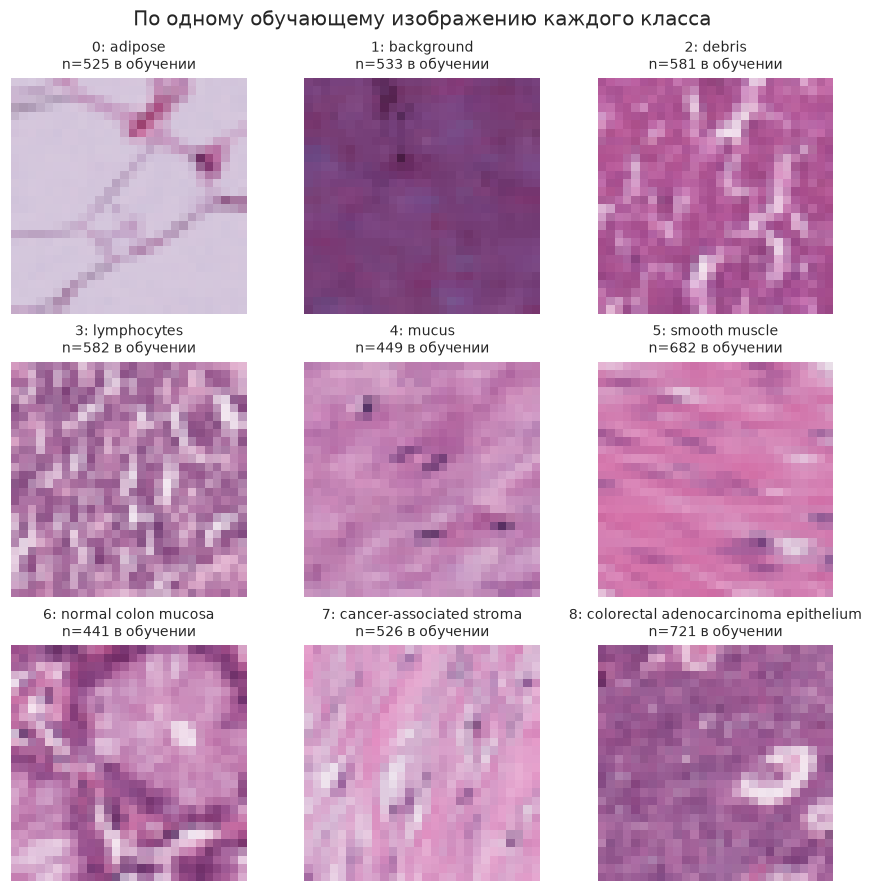

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8), layout="constrained")
for c, ax in zip(CLASSES, axes.flat):
    idx = train_idx[np.flatnonzero(targets[train_idx] == c)[0]]
    ax.imshow(images[idx])
    ax.set_title(f"{c}: {label_names[c]}\nn={counts.loc[c, 'Обучение']} в обучении", fontsize=9)
    ax.axis("off")
fig.suptitle("По одному обучающему изображению каждого класса")
save_figure("class_examples.png")

## Подготовка и CNN
Пиксели перевёл в [0, 1], затем нормализовал со средним 0.5 и стандартным
отклонением 0.5, как требует условие. Получается диапазон [-1, 1].
На обучении случайно отражаю изображения по горизонтали и вертикали:
ориентация фрагмента ткани не должна определять его класс.

В сети три свёрточных блока на 32, 64 и 128 каналов, BatchNorm и ReLU.
Затем усреднение по участкам, полносвязный слой и Dropout 0.25.
Выходов девять. Взвешенная CrossEntropy учитывает разное число примеров классов.

In [4]:
image_tensors = torch.from_numpy(images.copy()).permute(0, 3, 1, 2).float().div(255).sub(0.5).div(0.5)
assert image_tensors.min() >= -1 and image_tensors.max() <= 1


def make_loader(idx, shuffle=False):
    dataset = TensorDataset(image_tensors[idx], torch.tensor(targets[idx], dtype=torch.long))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)


class TissueCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((2, 2)), nn.Flatten(),
            nn.Linear(128 * 2 * 2, 128), nn.ReLU(), nn.Dropout(0.25), nn.Linear(128, 9),
        )

    def forward(self, x):
        return self.layers(x)


train_loader = make_loader(train_idx, shuffle=True)
train_eval_loader = make_loader(train_idx)
valid_loader = make_loader(valid_idx)
class_counts = np.bincount(targets[train_idx], minlength=9)
class_weights = torch.tensor(len(train_idx) / (9 * class_counts), dtype=torch.float32)
model = TissueCNN()
criterion = nn.CrossEntropyLoss(weight=class_weights)
criterion_sum = nn.CrossEntropyLoss(weight=class_weights, reduction="sum")
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=3, factor=0.5)
print(f"Параметров сети: {sum(p.numel() for p in model.parameters()):,}")


def evaluate(loader):
    model.eval()
    total_loss, total_weight = 0.0, 0.0
    all_logits, all_targets = [], []
    with torch.inference_mode():
        for inputs, labels in loader:
            logits = model(inputs)
            total_loss += criterion_sum(logits, labels).item()
            total_weight += class_weights[labels].sum().item()
            all_logits.append(logits)
            all_targets.append(labels)
    true = torch.cat(all_targets).numpy()
    probabilities = torch.cat(all_logits).softmax(dim=1).numpy()
    prediction = probabilities.argmax(axis=1)
    return {"loss": total_loss / total_weight, "accuracy": accuracy_score(true, prediction),
            "macro_f1": f1_score(true, prediction, labels=CLASSES, average="macro", zero_division=0),
            "prediction": prediction, "probabilities": probabilities}

Параметров сети: 160,521


## Обучение
Максимум 40 эпох. Сохраняю состояние с лучшим macro F1 на валидации;
после восьми эпох без улучшения останавливаюсь. Если качество перестало
расти, уменьшаю шаг Adam. Метрики обучения считаю без отражений и с
отключённым Dropout, чтобы кривые можно было сравнивать с валидацией.

In [5]:
history_rows = []
best_f1, best_epoch, wait, best_state = -1.0, 0, 0, None
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for inputs, labels in train_loader:
        horizontal = torch.rand(len(inputs)) < 0.5
        vertical = torch.rand(len(inputs)) < 0.5
        inputs[horizontal] = inputs[horizontal].flip(3)
        inputs[vertical] = inputs[vertical].flip(2)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(inputs), labels)
        assert torch.isfinite(loss)
        loss.backward()
        optimizer.step()
    train_result, valid_result = evaluate(train_eval_loader), evaluate(valid_loader)
    history_rows.append({"epoch": epoch, "train_loss": train_result["loss"], "valid_loss": valid_result["loss"],
                         "train_accuracy": train_result["accuracy"], "valid_accuracy": valid_result["accuracy"],
                         "train_f1": train_result["macro_f1"], "valid_f1": valid_result["macro_f1"]})
    scheduler.step(valid_result["macro_f1"])
    if valid_result["macro_f1"] > best_f1:
        best_f1, best_epoch = valid_result["macro_f1"], epoch
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
    print(f"Эпоха {epoch:02d}: train F1={train_result['macro_f1']:.3f}, "
          f"val F1={valid_result['macro_f1']:.3f}, val loss={valid_result['loss']:.3f}")
    if wait >= PATIENCE:
        break
assert best_state is not None
model.load_state_dict(best_state)
history = pd.DataFrame(history_rows)
history.to_csv(OUT / "training_history.csv", index=False)
print(f"Выбрана эпоха {best_epoch}: validation macro F1={best_f1:.3f}.")

Эпоха 01: train F1=0.522, val F1=0.509, val loss=1.181


Эпоха 02: train F1=0.700, val F1=0.701, val loss=0.831


Эпоха 03: train F1=0.738, val F1=0.736, val loss=0.732


Эпоха 04: train F1=0.705, val F1=0.691, val loss=0.824


Эпоха 05: train F1=0.830, val F1=0.826, val loss=0.479


Эпоха 06: train F1=0.728, val F1=0.729, val loss=0.724


... (30 outputs left out)

Эпоха 37: train F1=0.958, val F1=0.926, val loss=0.222


Эпоха 38: train F1=0.962, val F1=0.928, val loss=0.218


Эпоха 39: train F1=0.960, val F1=0.921, val loss=0.227


Эпоха 40: train F1=0.962, val F1=0.923, val loss=0.217
Выбрана эпоха 38: validation macro F1=0.928.


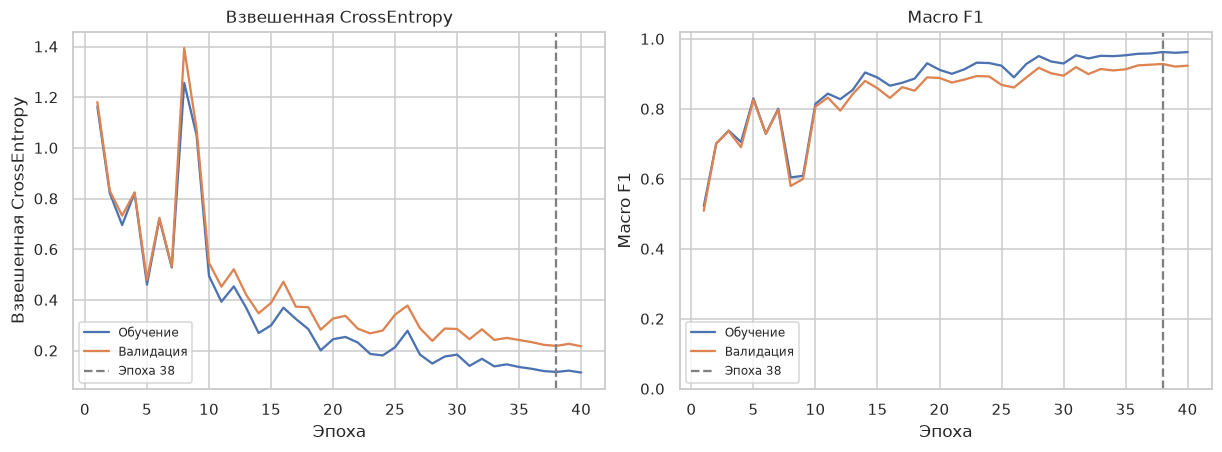

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric, title in [(axes[0], "loss", "Взвешенная CrossEntropy"), (axes[1], "f1", "Macro F1")]:
    ax.plot(history.epoch, history[f"train_{metric}"], label="Обучение")
    ax.plot(history.epoch, history[f"valid_{metric}"], label="Валидация")
    ax.axvline(best_epoch, color="gray", linestyle="--", label=f"Эпоха {best_epoch}")
    ax.set(xlabel="Эпоха", ylabel=title, title=title)
    ax.legend(fontsize=8)
axes[1].set_ylim(0, 1.02)
save_figure("training_curves.png")

## Проверка выбранной модели
Ниже оцениваю зафиксированную сеть на внутреннем тесте. Для сравнения
добавил ответ самым частым обучающим классом. По внешнему архиву меток нет,
поэтому его качество отдельно оценить нельзя.

,Accuracy,Macro F1
Выборка,,
"Частый класс, внутренний тест",0.143,0.028
"CNN, валидация",0.928,0.928
"CNN, внутренний тест",0.930,0.930


,precision,recall,f1-score,support,Название
0,1.000,0.938,0.968,113.0,adipose
1,1.000,1.000,1.000,114.0,background
2,0.902,0.887,0.894,124.0,debris
3,0.984,0.992,0.988,125.0,lymphocytes
4,0.883,0.948,0.915,96.0,mucus
5,0.956,0.890,0.922,146.0,smooth muscle
6,0.976,0.874,0.922,95.0,normal colon mucosa
7,0.798,0.876,0.835,113.0,cancer-associated stroma
8,0.896,0.955,0.925,154.0,colorectal adenocarcinoma epithelium


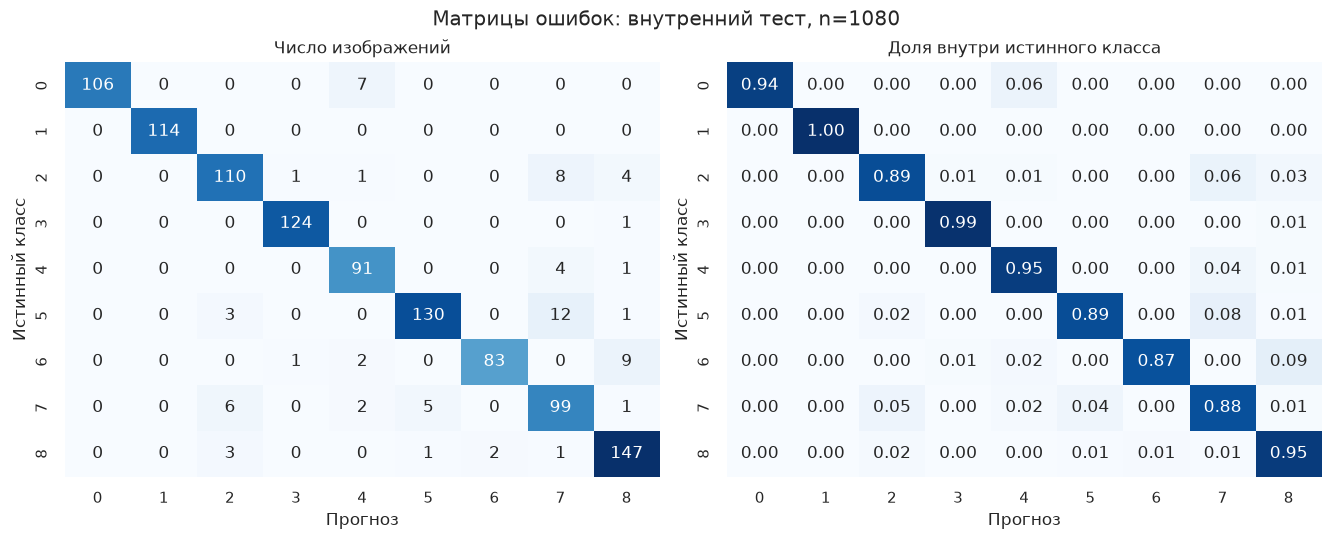

In [7]:
valid_result = evaluate(valid_loader)
test_result = evaluate(make_loader(test_idx))
baseline = np.full(len(test_idx), np.argmax(class_counts))
metric_table = pd.DataFrame([
    {"Выборка": "Частый класс, внутренний тест", "Accuracy": accuracy_score(targets[test_idx], baseline),
     "Macro F1": f1_score(targets[test_idx], baseline, labels=CLASSES, average="macro", zero_division=0)},
    {"Выборка": "CNN, валидация", "Accuracy": valid_result["accuracy"], "Macro F1": valid_result["macro_f1"]},
    {"Выборка": "CNN, внутренний тест", "Accuracy": test_result["accuracy"], "Macro F1": test_result["macro_f1"]},
]).set_index("Выборка")
display(metric_table.round(3))
metric_table.to_csv(OUT / "metrics.csv")
class_report = classification_report(targets[test_idx], test_result["prediction"], labels=CLASSES,
                                     output_dict=True, zero_division=0)
per_class = pd.DataFrame({str(c): class_report[str(c)] for c in CLASSES}).T
per_class["Название"] = label_names
per_class.to_csv(OUT / "per_class_metrics.csv", index_label="Класс")
display(per_class.round(3))
cm = confusion_matrix(targets[test_idx], test_result["prediction"], labels=CLASSES)
internal = pd.DataFrame({"image_id": image_ids[test_idx], "target": targets[test_idx], "prediction": test_result["prediction"]})
for c in CLASSES:
    internal[f"p_{c}"] = test_result["probabilities"][:, c]
internal.to_csv(OUT / "internal_test_predictions.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", vmin=0, vmax=1,
            cmap="Blues", cbar=False, ax=axes[1])
for ax, title in zip(axes, ["Число изображений", "Доля внутри истинного класса"]):
    ax.set(xlabel="Прогноз", ylabel="Истинный класс", title=title)
fig.suptitle(f"Матрицы ошибок: внутренний тест, n={len(test_idx)}")
save_figure("confusion_matrix.png")

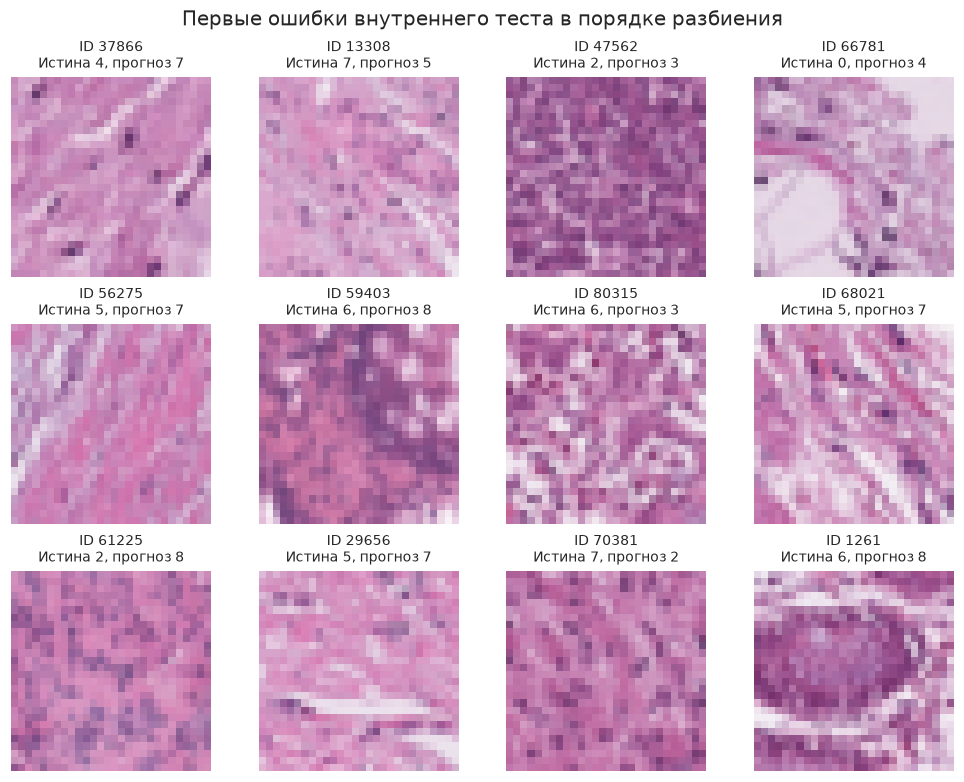

In [8]:
wrong = np.flatnonzero(targets[test_idx] != test_result["prediction"])
fig, axes = plt.subplots(3, 4, figsize=(9, 7), layout="constrained")
for ax, position in zip(axes.flat, wrong[:12]):
    row = test_idx[position]
    ax.imshow(images[row])
    ax.set_title(f"ID {image_ids[row]}\nИстина {targets[row]}, прогноз {test_result['prediction'][position]}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Первые ошибки внутреннего теста в порядке разбиения")
save_figure("error_examples.png")

## Итоговые прогнозы
Использую тот же checkpoint, что прошёл внутренний тест. Пиксели внешних
изображений преобразую по той же фиксированной формуле. ID сохраняю без изменений.

In [9]:
with np.load(external_path, allow_pickle=False) as archive:
    external_images = archive["images"]
    external_ids = archive["image_id"]
assert external_images.dtype == np.uint8 and external_images.shape[1:] == (28, 28, 3)
assert len(np.unique(external_ids)) == len(external_ids)
assert set(external_ids).isdisjoint(image_ids)
external_tensor = torch.from_numpy(external_images.copy()).permute(0, 3, 1, 2).float().div(255).sub(0.5).div(0.5)
model.eval()
with torch.inference_mode():
    external_prediction = torch.cat([model(batch).argmax(1) for batch in external_tensor.split(BATCH_SIZE)]).numpy()
submission = pd.DataFrame({"image_id": external_ids, "prediction": external_prediction})
assert len(submission) == len(external_ids) and not submission.isna().any().any()
assert set(submission.prediction) <= set(CLASSES)
np.testing.assert_array_equal(submission.image_id, external_ids)
submission.to_csv(ROOT / "outputs/task3_1_predictions.csv", index=False)
torch.save(model.state_dict(), OUT / "model.pt")
print(f"Сохранено {len(submission)} прогнозов.")
display(submission.head())

Сохранено 1800 прогнозов.


,image_id,prediction
0,100,3
1,130,0
2,156,5
3,169,5
4,248,3


## Выводы
Классы обозначены числами 0–8; их названия приведены в первой таблице.
Метрики ниже относятся к внутреннему тесту и не оценивают диагностику на новых пациентах.

In [10]:
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
a, b = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
weakest = per_class["f1-score"].idxmin()
report = (
    "Королев Даниил, 636-02. Задание 3.1.\n\n"
    f"Взял {len(images)} RGB-изображений 28×28 из локального PathMNIST, девять классов. "
    f"Разделил их на обучение/валидацию/внутренний тест: {len(train_idx)}/{len(valid_idx)}/{len(test_idx)}, "
    "со стратификацией, seed=42. Пиксели перевёл в [0,1], затем нормализовал "
    "со средним и стандартным отклонением 0.5. На обучении использовал отражения.\n\n"
    "CNN: три свёртки 32/64/128 с BatchNorm и ReLU, MaxPool, AdaptiveAvgPool, "
    "полносвязный слой и Dropout 0.25. Обучал Adam с взвешенной CrossEntropy; "
    "веса классов считал только по обучению. "
    f"По macro F1 валидации выбрана эпоха {best_epoch} из {len(history)}. "
    f"На валидации Accuracy={valid_result['accuracy']:.3f}, macro F1={valid_result['macro_f1']:.3f}.\n\n"
    f"На внутреннем тесте Accuracy={test_result['accuracy']:.3f}, macro F1={test_result['macro_f1']:.3f}. "
    f"Хуже всего различается класс {weakest} ({label_names[int(weakest)]}), "
    f"F1={per_class.loc[weakest, 'f1-score']:.3f}. Самая частая направленная ошибка: "
    f"{a}→{b}, {off_diagonal[a,b]} изображений. Цвет и текстура тканей могут быть похожи; "
    "при размере 28×28 часть деталей теряется. Это возможное объяснение, а не доказанная причина.\n\n"
    f"Сохранил {len(submission)} внешних прогнозов с исходными ID. Метки внешнего архива "
    "не использовал. Исходные данные и vanilla-code не менял. Идентификаторов пациентов "
    "нет, поэтому разделение по изображениям не доказывает перенос на новые препараты "
    "и пациентов. Для улучшения нужны проверка на независимых данных и анализ ошибок "
    "по классам; оценивать работу врача по этой учебной модели нельзя."
)
assert len(report) <= 2000, len(report)
_ = (ROOT / "your-sollution/task3_1_report.md").write_text(report + "\n", encoding="utf-8")
display(Markdown(report))
print(f"Отчёт: {len(report)} знаков.")
summary = {"author": "Королев Даниил", "group": "636-02", "seed": SEED, "device": "cpu",
           "train_rows": len(train_idx), "validation_rows": len(valid_idx), "internal_test_rows": len(test_idx),
           "external_rows": len(external_ids), "best_epoch": best_epoch, "epochs_run": len(history),
           "validation_accuracy": valid_result["accuracy"], "validation_macro_f1": valid_result["macro_f1"],
           "internal_test_accuracy": test_result["accuracy"], "internal_test_macro_f1": test_result["macro_f1"],
           "confusion_matrix": cm.tolist(), "class_weights": class_weights.tolist(),
           "python": platform.python_version(), "torch": torch.__version__,
           "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [train_path, external_path]},
           "predictions_sha256": hashlib.sha256((ROOT / "outputs/task3_1_predictions.csv").read_bytes()).hexdigest()}
_ = (OUT / "run_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

Королев Даниил, 636-02. Задание 3.1.

Взял 7200 RGB-изображений 28×28 из локального PathMNIST, девять классов. Разделил их на обучение/валидацию/внутренний тест: 5040/1080/1080, со стратификацией, seed=42. Пиксели перевёл в [0,1], затем нормализовал со средним и стандартным отклонением 0.5. На обучении использовал отражения.

CNN: три свёртки 32/64/128 с BatchNorm и ReLU, MaxPool, AdaptiveAvgPool, полносвязный слой и Dropout 0.25. Обучал Adam с взвешенной CrossEntropy; веса классов считал только по обучению. По macro F1 валидации выбрана эпоха 38 из 40. На валидации Accuracy=0.928, macro F1=0.928.

На внутреннем тесте Accuracy=0.930, macro F1=0.930. Хуже всего различается класс 7 (cancer-associated stroma), F1=0.835. Самая частая направленная ошибка: 5→7, 12 изображений. Цвет и текстура тканей могут быть похожи; при размере 28×28 часть деталей теряется. Это возможное объяснение, а не доказанная причина.

Сохранил 1800 внешних прогнозов с исходными ID. Метки внешнего архива не использовал. Исходные данные и vanilla-code не менял. Идентификаторов пациентов нет, поэтому разделение по изображениям не доказывает перенос на новые препараты и пациентов. Для улучшения нужны проверка на независимых данных и анализ ошибок по классам; оценивать работу врача по этой учебной модели нельзя.

Отчёт: 1297 знаков.
